<a href="https://colab.research.google.com/github/AntonGMorris/AntonGMorris/blob/main/lab3_machinelearning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Linear Regression, PCA and LDA**

Lab 3

**Anton Morris - 2274309**

Refrences:
https://scikit-learn.org/stable/modules/generated/sklearn.decomposition.PCA.html

In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn as sk
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.decomposition import PCA
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis


**Task 3.1**

load data
print data for shape

In [8]:
x_train_data = np.load('x_values-1.npy')
y_train_data = np.load('y_values-1.npy')

print(x_train_data.shape)
print(y_train_data.shape)

test_x_values = np.load("test_x_values-1.npy")

print(test_x_values.shape)



(10, 1)
(10, 1)
(100, 1)


Test plot to see if everything pulls correctly

Text(0.5, 0, 'x')

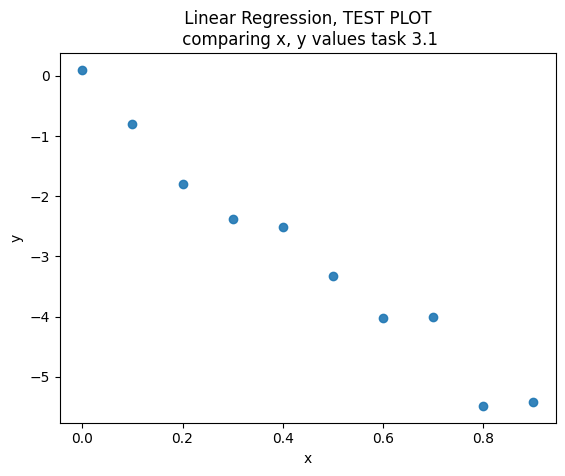

In [9]:
scatter = plt.scatter(x_train_data, y_train_data, alpha=0.9)


plt.title(" Linear Regression, TEST PLOT \n comparing x, y values task 3.1")
plt.ylabel("y")
plt.xlabel("x")

final plot to show Linear Regression results

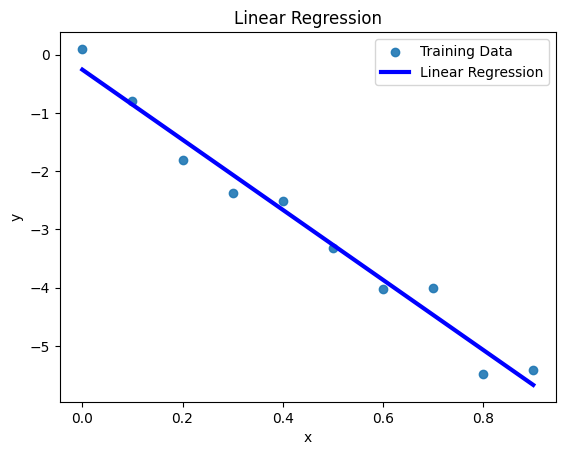

In [10]:
from matplotlib import legend
model = LinearRegression()
model.fit(x_train_data.reshape(-1, 1), y_train_data)

y_pred = model.predict(x_train_data.reshape(-1, 1))

scatter_trained = plt.scatter(
    x_train_data,
    y_train_data,
    label="Training Data",
    alpha=0.9
    )

plt.plot(
    x_train_data,
    y_pred,
    color="blue",
    label="Linear Regression",
    linewidth=3
    )

plt.title("Linear Regression")
plt.ylabel("y")
plt.xlabel("x")
plt.legend()
plt.show()

**Task 3.2**
Principle component analysis wtih sklearn

loading wine data

In [11]:
wineData = np.load("wineData-1.npy")
wineLabels = np.load("wineLabels-1.npy")

print(wineData.shape)
print(wineLabels.shape)

print(wineData)
print(wineLabels)


(178, 13)
(178,)
[[1.362e+01 4.950e+00 2.350e+00 ... 9.100e-01 2.050e+00 5.500e+02]
 [1.182e+01 1.720e+00 1.880e+00 ... 9.400e-01 2.440e+00 4.150e+02]
 [1.388e+01 5.040e+00 2.230e+00 ... 5.800e-01 1.330e+00 4.150e+02]
 ...
 [1.225e+01 1.730e+00 2.120e+00 ... 1.000e+00 3.170e+00 5.100e+02]
 [1.330e+01 1.720e+00 2.140e+00 ... 1.020e+00 2.770e+00 1.285e+03]
 [1.251e+01 1.240e+00 2.250e+00 ... 7.500e-01 1.510e+00 6.500e+02]]
[2 1 2 2 2 2 1 2 0 2 0 0 0 1 2 2 0 0 2 0 2 2 0 1 1 0 1 2 0 0 2 1 0 0 2 0 0
 2 1 0 0 1 1 0 1 0 0 2 2 1 1 1 2 0 1 2 0 2 2 0 0 1 1 0 1 0 1 1 0 2 1 1 1 1
 0 1 2 0 2 1 1 1 1 2 0 0 1 2 0 1 0 0 0 0 1 1 0 2 2 0 1 0 2 2 0 2 0 1 1 0 0
 1 1 1 0 2 1 0 1 1 1 1 1 1 2 1 1 2 2 1 0 1 1 2 1 1 0 1 2 2 1 0 1 1 2 0 0 2
 0 2 2 1 2 1 0 1 1 2 1 1 0 1 0 1 1 1 2 0 1 2 0 0 1 0 1 1 0 2]


Dividing the data into training / test split

In [12]:
split= int(len(wineData) * 0.8)  # 142

train_data = wineData[:split]
train_labels = wineLabels[:split]

test_data = wineData[split:]      # Starts right where train ends (no overlap!)
test_labels = wineLabels[split:]

print(train_data.shape)
print(train_labels.shape)

print(test_data.shape)
print(test_labels.shape)



(142, 13)
(142,)
(36, 13)
(36,)


Scatter plot of train / test split

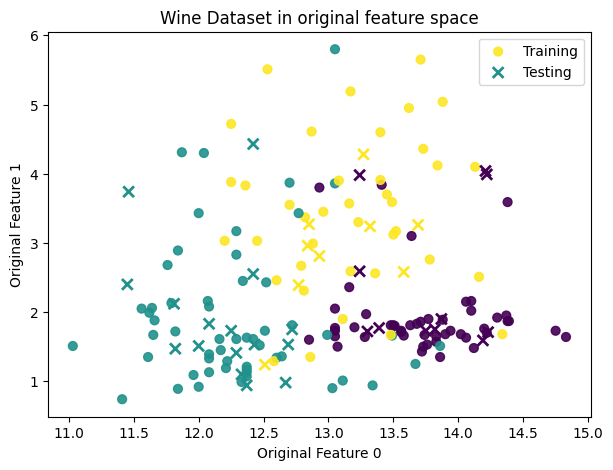

In [13]:
plt.figure(figsize=(7, 5))

plt.scatter(
    train_data[:, 0],
    train_data[:, 1],
    c=train_labels,
    marker='o',
    label='Training',
    alpha=0.9,
    s=40
)

plt.scatter(
    test_data[:, 0],
    test_data[:, 1],
    c=test_labels,
    marker='x',
    label='Testing',
    alpha=1.0,
    s=60,
    linewidths=2
)

plt.title("Wine Dataset in original feature space")
plt.xlabel("Original Feature 0")
plt.ylabel("Original Feature 1")
plt.legend()
plt.show()



Task 3.2 PCA Analysis with sklearn

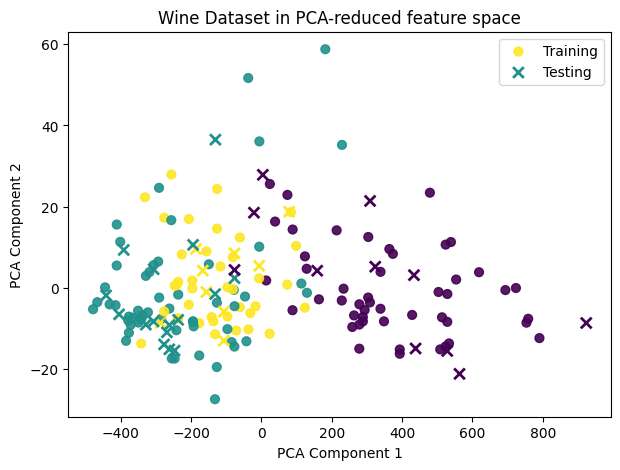

In [14]:
pca = PCA(n_components=2)

train_data_pca = pca.fit_transform(train_data)
test_data_pca = pca.transform(test_data)

plt.figure(figsize=(7, 5))

plt.scatter(
    train_data_pca[:, 0],
    train_data_pca[:, 1],
    c=train_labels,
    marker='o',
    label='Training',
    alpha=0.9,
    s=40
)

plt.scatter(
    test_data_pca[:, 0],
    test_data_pca[:, 1],
    c=test_labels,
    marker='x',
    label='Testing',
    alpha=1.0,
    s=60,
    linewidths=2
)

plt.title("Wine Dataset in PCA-reduced feature space")
plt.xlabel("PCA Component 1")
plt.ylabel("PCA Component 2")
plt.legend()
plt.show()

Task 3.3 - LDA with sklearn

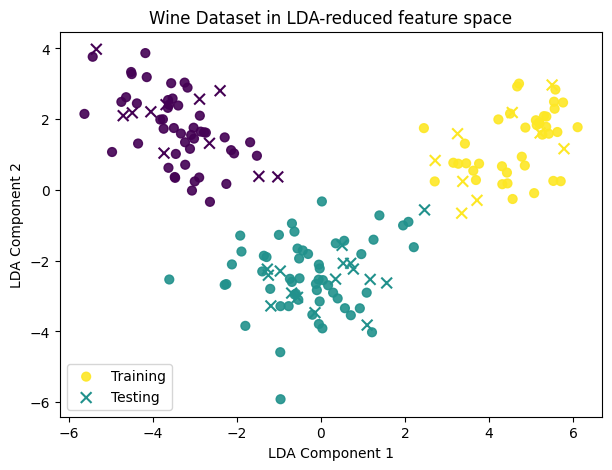

In [18]:
lda = LinearDiscriminantAnalysis(n_components=2)

train_data_lda = lda.fit_transform(train_data, train_labels)
test_data_lda = lda.transform(test_data)

plt.figure(figsize=(7, 5))

plt.scatter(
    train_data_lda[:, 0],
    train_data_lda[:, 1],
    c=train_labels,
    marker='o',
    label='Training',
    alpha=0.9,
    s=40
)

plt.scatter(
    test_data_lda[:, 0],
    test_data_lda[:, 1],
    c=test_labels,
    marker='x',
    label='Testing',
    alpha=1.0,
    s=60,
)

plt.title("Wine Dataset in LDA-reduced feature space")
plt.xlabel("LDA Component 1")
plt.ylabel("LDA Component 2")
plt.legend()
plt.show()


Task 3.4 PCA by hand

Question:
PCA (Unsupervised): Focuses solely on finding orthogonal directions of maximum total variance in the feature space without knowledge of class labels. Because variance doesn't necessarily align with class boundaries, the resulting clusters overlap considerably in the 2D PCA space.

LDA (Supervised): Incorporates class labels to find a subspace that maximizes the distance between class means (between class variance) while minimizing the variance within each class (intra class variance). This leads to more distinct separation and tigher more defined clusters for the three wine types compared to PCA.